<a href="https://colab.research.google.com/github/azrasugec/HYPERSPECTRAL/blob/main/module_2/01_Tanager_Real_Data_Explorer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploring Real-World Tanager-1 Data
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/planetlabs/tanager-opendata-edu/blob/main/module_2/01_Tanager_Real_Data_Explorer.ipynb)

**Welcome to the first lesson in module 2.**

In Lessons 2 and 3 of the previous module, we created a synthetic dataset and used it to learn the fundamental principles of HDF5.

In this lesson, we transition to working with real, **operational Tanager-1 Science Data**.

While the real data files are significantly larger and the hierarchy is more complex, the underlying mechanics remain identical. So, you will use the same workflows you have learned to work with real data.

```{note}
**This module also starts your Toolkit.** As you work through Module 2, you will collect the reusable functions you write into a single **Toolkit** cell and grow it lesson by lesson. By the end of the course, that cell is your own hyperspectral analysis library. We start it at the end of *this* lesson.
```

Let's begin!

## Data Acquisition: Selecting a Scene

To analyze real data, we need to retrieve a sample from the **Planet Tanager STAC Catalog**.

> **💡 For this lesson,** we've selected a **specific scene** and the **Basic Surface Reflectance** (`basic_sr_hdf5`) asset so everyone follows the same example. Tanager-1 captures the full spectral fingerprint of the Earth across many domains (Agriculture, Water, Mineralogy, etc.). If you prefer a different theme or location, follow the [**Open Data STAC**](../access/open_stac.md) tutorial to pick your own scene, then either copy the asset URL into the download cell or download the file to your workspace. The workflow you learn here applies to any Tanager-1 data you choose.

```{important}
Each scene lists several asset products (radiance, ortho, masks, etc.). This lesson uses **`basic_sr_hdf5`** only. The following lessons in Module 2 will cover the other asset types and when to use them.

For the most reliable results in Colab, run this notebook from top to bottom, in order. Several cells depend on variables or objects created in earlier cells. If you restart the runtime or run cells out of sequence you may get an error. You will need to rerun the notebook starting from the first code cell.
```
---


<img class="thumbnail-enhanced" src="https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/thumbnail/20250510_005001_00_4001_thumb.png"
     alt="Tanager 1"
     width="800">

>Pilliga, Narrabri Shire Council, New South Wales, 2388, Australia

In [1]:
# Essential imports for this lesson
import numpy as np              # For numerical operations and arrays
import h5py
import matplotlib.pyplot as plt # For creating plots and visualizations
import os                       # For operating system functionalities, e.g., file checks

In [2]:
# Download the Tanager-1 Basic SR HDF5 file
import urllib.request

url = "https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/basic_sr_hdf5/20250510_005001_00_4001_basic_sr_hdf5.h5"
file_path = "20250510_005001_00_4001_basic_sr_hdf5.h5"

def _progress(count, block_size, total_size):
    mb_done = count * block_size / 1_000_000
    mb_total = total_size / 1_000_000
    print(f"\rDownloading... {mb_done:.1f} / {mb_total:.1f} MB", end="", flush=True)

if not os.path.exists(file_path):
    urllib.request.urlretrieve(url, file_path, reporthook=_progress)
    print(f"\nDownload complete: {file_path}")
else:
    print(f"File already exists, skipping download: {file_path}")

if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"File '{file_path}' not found.\n"
        "Please run the download cell above, or upload the file to your session."
    )

print(f"File ready: {file_path}")

Downloading... 844.2 / 844.2 MB
Download complete: 20250510_005001_00_4001_basic_sr_hdf5.h5
File ready: 20250510_005001_00_4001_basic_sr_hdf5.h5


## Navigating Real Tanager-1 Hierarchies

As you remember from the previous lesson, if we tried to check `f.keys()` manually for every folder, it would take forever.

Instead, we will deploy an upgraded version of our Recursive Tree `print_structure` function.

**What's upgraded:**

| | Previous version | Upgraded version |
| --- | --- | --- |
| **Shows** | Path names only | Path names + **Metadata (Attributes)** for every object |
| **Benefit** | — | Inspect attributes on groups and datasets |


In [3]:
def print_structure(name, obj) -> None:
    """
    Enhanced Recursive Tree Viewer that prints structure AND metadata.
    """
    # 1. Calculate Indentation (Visual Depth)
    level = name.count('/')
    indent = '    ' * level

    # 2. Identify Type (Group or Dataset)
    if isinstance(obj, h5py.Group):
        icon = "📂"
        print(f"{indent}{icon} {name}/")
    elif isinstance(obj, h5py.Dataset):
        icon = "📄"
        # For datasets, we also print the shape/type
        print(f"{indent}{icon} {name} | {obj.shape} | {obj.dtype}")

    # 3. METADATA DUMP: Print all Attributes attached to this object
    # We use a distinct symbol (↳) to show these are "attributes"
    if len(obj.attrs) > 0:
        for key, val in obj.attrs.items():
            # Truncate very long attribute values to keep output readable
            val_str = str(val)
            if len(val_str) > 50:
                val_str = val_str[:50] + "..."

            print(f"{indent}    ↳ 🏷️ {key}: {val_str}")

# Note: We use the 'file_path' variable defined in the previous cell
print(f"--- 🕵️ Initiating Structural Audit of: {file_path} ---\n")

with h5py.File(file_path, 'r') as f:
    f.visititems(print_structure)

--- 🕵️ Initiating Structural Audit of: 20250510_005001_00_4001_basic_sr_hdf5.h5 ---

📂 HDFEOS/
    📂 HDFEOS/ADDITIONAL/
        📂 HDFEOS/ADDITIONAL/FILE_ATTRIBUTES/
    📂 HDFEOS/SWATHS/
        📂 HDFEOS/SWATHS/HYP/
            ↳ 🏷️ created_at: 2025-12-05T23:23:41.371559+00:00
            ↳ 🏷️ strip_id: 20250510_005001_00_4001_strip
            📂 HDFEOS/SWATHS/HYP/Data Fields/
                📄 HDFEOS/SWATHS/HYP/Data Fields/aerosol_optical_depth | (502, 607) | float32
                    ↳ 🏷️ Unit: Unitless
                    ↳ 🏷️ _FillValue: -9999.0
                📄 HDFEOS/SWATHS/HYP/Data Fields/beta_cirrus_mask | (502, 607) | uint8
                    ↳ 🏷️ _FillValue: 255
                📄 HDFEOS/SWATHS/HYP/Data Fields/beta_cloud_mask | (502, 607) | uint8
                    ↳ 🏷️ _FillValue: 255
                📄 HDFEOS/SWATHS/HYP/Data Fields/column_water_vapour | (502, 607) | float32
                    ↳ 🏷️ Unit: g/cm^2
                    ↳ 🏷️ _FillValue: -9999.0
                

Interesting! Scroll through the output you just generated. You will see dozens of groups and datasets.

**Do not get overwhelmed!**

This is a standard **HDF-EOS** layout. Let's break down exactly what we found.

**The Roots**

You will see two main groups within the root of HDF5 file: `HDFEOS/` and `HDFEOS INFORMATION/`.

* **`HDFEOS/`**: This is the most extensive group. It contains all the actual scientific datasets (📄).

* **`HDFEOS INFORMATION/`**: This largely contains structural metadata.

**The Critical Paths**

If you look closer at the map, you will find the two main groups that contain the data we most care about:

1. **`HDFEOS/SWATHS/HYP/Data Fields/`**: This holds the science data (Reflectance, Cloud Masks, etc.).
2. **`HDFEOS/SWATHS/HYP/Geolocation Fields/`**: This holds the location data (Latitude, Longitude, Time).

**The Attributes**

The map also reveals the attributes (metadata). Remember, attributes are stored as **Key-Value** pairs.

*Example:* One of the attributes of the `surface_reflectance` dataset is named `wavelengths` (Key), and its value is a list of numbers representing the center wavelengths for each spectral band.

```{note} In Python
To retrieve an attribute, you must know its exact **Key** name (e.g., `'wavelengths'` or `'units'`). We will show how to do this in the next section.
```

```{admonition} Structure Consistency
:class: important

**Within an asset type:** The internal structure is **fixed** across all scenes. Every `basic_sr_hdf5` file has the same folder paths and dataset names, regardless of date or location.

**Across asset types:** The structure **changes**. Examples:

- `basic_radiance_hdf5` — different variable name for the hyperspectral dataset than the reflectance file
- `ortho_sr_hdf5` — slightly different internal layout

**Takeaway:** Always remember or check the structure when you switch to a new asset type.
```

## Understanding the Data Fields

Here is the breakdown of the **`HDFEOS/SWATHS/HYP/Data Fields/`** group, organized into a single clear table.

### Tanager Basic SR Data Fields

*This helps you decide which datasets you actually need.*

| Dataset name (HDF5 field)&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; | Summary |
| --- | --- |
| **`surface_reflectance`** | **Category:** Core Science<br>**Description:** Bottom-of-Atmosphere (BOA) hyperspectral cube (*Wavelengths x Rows x Columns*)<br>**Primary Application:** Deriving science products: Calculating vegetation indices, mapping minerals, and training classification models. |
| **`surface_reflectance_uncertainty`** | **Category:** Quality Assurance<br>**Description:** Per-pixel statistical uncertainty of the reflectance<br>**Primary Application:** Evaluating data confidence: Understanding and incorporating the uncertainty of the estimated surface reflectance. |
| **`beta_cloud_mask`** | **Category:** Masking<br>**Description:** Binary mask indicating cloud presence (*Beta product*)<br>**Primary Application:** Filtering usable data: Excluding cloud-obstructed pixels from spectral analysis. |
| **`beta_cirrus_mask`** | **Category:** Masking<br>**Description:** Binary mask for thin, semi-transparent clouds<br>**Primary Application:** Filtering usable data: Identifying pixels where cirrus clouds might distort sensitive spectral bands. |
| **`nodata_pixels`** | **Category:** Masking<br>**Description:** Binary mask indicating missing or invalid sensor data<br>**Primary Application:** Filtering usable data: Masking image edges or invalid measurements. |
| **`aerosol_optical_depth`** | **Category:** Atmosphere<br>**Description:** Measure of airborne particles (e.g., dust, smoke)<br>**Primary Application:** Assessing atmospheric clarity: Understanding the relative thickness of aerosols estimated for each pixel. _Note this is not currently a validated measurement_. |
| **`column_water_vapour`** | **Category:** Atmosphere<br>**Description:** Total concentration of atmospheric water vapor present in the column<br>**Primary Application:** Understanding atmospheric absorption: Seeing the amount of water vapor estimated to be in the atmosphere for each pixel. _Note this is not currently a validated measurement_. |
| **`sun_zenith` / `sun_azimuth`** | **Category:** Geometry<br>**Description:** Solar position (Zenith = degrees from nadir; Azimuth = degrees from N)<br>**Primary Application:** Understanding illumination: Normalizing shadows, correcting terrain effects, and BRDF modeling. |
| **`sensor_zenith` / `sensor_azimuth`** | **Category:** Geometry<br>**Description:** Satellite viewing angle in degrees from nadir and orientation from north<br>**Primary Application:** Correcting off-nadir effects: Adjusting for distortions when the satellite is not looking straight down. |
| **`sensor_to_ground_path_length`** | **Category:** Geometry<br>**Description:** The physical distance the light travels from the ground to the sensor<br>**Primary Application:** Radiative transfer modeling: Used in advanced atmospheric correction algorithms. |

```{admonition} Shared Datasets vs. Basic-Only Geolocation
:class: important

**Common across Basic and Ortho:** The Data Fields group (masks, atmosphere, geometry) is shared across all asset types. Datasets such as `beta_cloud_mask`, `beta_cirrus_mask`, `nodata_pixels`, `aerosol_optical_depth`, `column_water_vapour`, `sun_zenith`, `sun_azimuth`, `sensor_zenith`, and `sensor_to_ground_path_length` exist in both Basic and Ortho products.

**Basic-only: Geolocation Fields** The **Geolocation Fields** group holds the **Latitude** and **Longitude** (and **Time**) of each pixel. This group exists **only in Basic assets**, Ortho products are already map-projected, so they do not include per-pixel coordinates.

We will explore the Basic vs. Ortho difference in depth in **Lesson 3 of Module 2**.
```

## Data Extraction

Now that we know the paths, we can perform a targeted extraction. We will load two items:

1. **The surface reflectance cube** — the 3D array (bands × rows × columns)
2. **The `wavelengths` attribute** — metadata that tells us which band corresponds to which wavelength

In [4]:
# 1. Define Your Targets
# We store the path in a variable so it's easy to change later
DATA_PATH = 'HDFEOS/SWATHS/HYP/Data Fields/surface_reflectance'

with h5py.File(file_path, 'r') as f:

    # 2. Point to the Dataset
    dset = f[DATA_PATH]

    # 3. Extract Metadata (The Wavelengths)
    # We use .get() so the code is safe even if metadata is missing
    wavelengths = dset.attrs.get('wavelengths')

    # 4. Load the 3D Cube into RAM
    # The [:] syntax commands Python to read the ENTIRE dataset.
    # Note: For a 1GB file, this might take a few seconds.
    reflectance_cube = dset[:]

    # 5. Slice a band for visualization
    band_image = reflectance_cube[50,:,:]

# Print a summary of the loaded data and metadata
print(f"   - Cube Shape: {reflectance_cube.shape} (Bands, Height (rows), Width (columns))")
print(f"   - Wavelengths: Found {len(wavelengths)} bands")

   - Cube Shape: (426, 502, 607) (Bands, Height (rows), Width (columns))
   - Wavelengths: Found 426 bands


**This is not the end** — we are going to explore Tanager-1 data deeply and the other assets in the rest of this module.


## Visualizing the Data

In the previous step, we extracted the full 3D cube and isolated a single 2D layer we named `band_image` (Band 50) for visualization.

Now, let's visualize that specific slice.

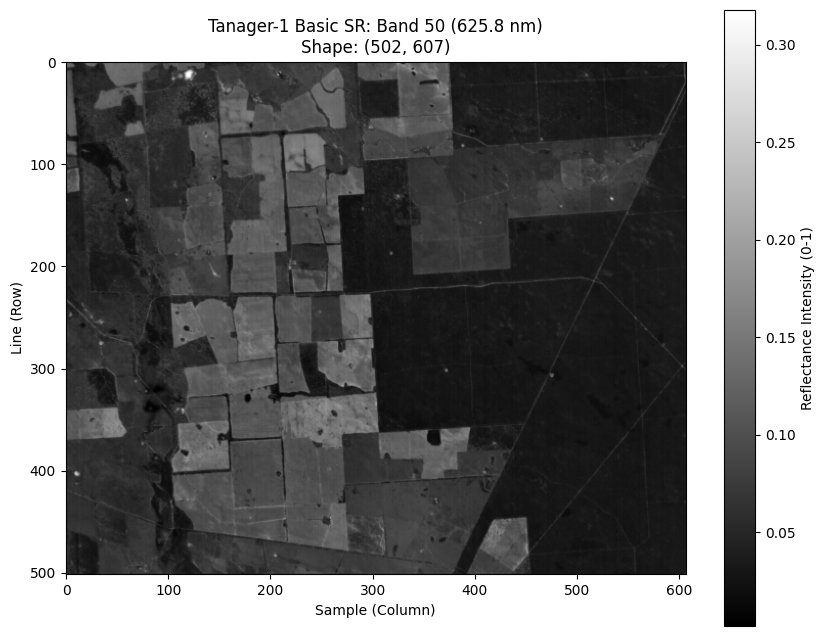

In [5]:
# Retrieve Wavelength Info
# Let's find out what part of the spectrum Band 50 represents
band_idx = 50
band_wavelength = wavelengths[band_idx]

# Plot the image using gray colormap to represent reflectance intensity using default min and max values
plt.figure(figsize=(10, 8))
plt.imshow(band_image, cmap='gray')

plt.colorbar(label='Reflectance Intensity (0-1)')

# Dynamic Title: Shows the physical Wavelength, not just the index
plt.title(f"Tanager-1 Basic SR: Band {band_idx} ({band_wavelength:.1f} nm)\nShape: {band_image.shape}")
plt.xlabel("Sample (Column)")
plt.ylabel("Line (Row)")

plt.show()

---

## Bonus: Understanding Image Contrast

Did you notice the image may look faint, washed our, or lacking detail? Did you notice there is a single very bright pixel group at the top of the image, while the rest of the scene appears darker and flat?

**What is happening?** Because Tanager is highly sensitive, it captures a large dynamic range. A single scene can contain incredibly dark features right alongside very bright ones. Some pixels in the scene may have genuinely extreme reflectance values — bright surfaces like clouds, bare soil, or specular highlights can reflect much more light than surrounding vegetation or water. Even a small number of these outlier pixels is enough to pull the displayed maximum far above the typical scene values, compressing most of the landscape into a narrow, indistinguishable band of gray.

### Why the image looks low-contrast by default

Most visualization tools map data values to grayscale like this:

* the **minimum** value → black
* the **maximum** value → white

If your array contains even a few unusually bright (or dark) outliers, the color mapping is forced to span that full range. As a result, the majority of pixels — the ones that actually represent the majority of the landscape — get squeezed into a narrow band of gray. That compression makes the image look flat and hides structure.

### How `plt.imshow()` works?

When you call `plt.imshow(band_image, cmap="gray")`, Matplotlib has to convert your numeric values into screen brightness. It does this in two steps:

1. **Normalize (scale) your data to a 0–1 range**
2. **Map 0 → black and 1 → white** using the chosen colormap (here, grayscale)

By default, `imshow()` chooses the scaling limits from your array:

* the **minimum** value → black (0)
* the **maximum** value → white (1)

{numref}`fig-imshow-contrast` illustrates this mapping:

```{figure} assets/images/explain_contrast.png
---
name: fig-imshow-contrast
alt: Diagram showing how imshow maps the minimum value to black and the maximum value to white, with all values in between stretched linearly across the grayscale range.
width: 700px
align: center
---
How `imshow()` maps data values to screen brightness by default: the array minimum becomes black and the array maximum becomes white. A single bright outlier forces the majority of pixels into a narrow, indistinguishable band of gray.
```

If your array contains even a few unusually bright (or dark) outliers, as was the case here, those extreme values become the `max` (or `min`).

### How we fix it

To improve visibility, we usually **don’t want to change the scientific values** stored in `band_image`, those reflectance numbers are meaningful and should remain untouched for analysis.

Instead, we need to take control of our visual contrast. In practice, this is done by choosing better display limits `plt.imshow()`:

* `vmin` = the value we want to appear **black**
* `vmax` = the value we want to appear **white**

Everything between `vmin` and `vmax` is stretched across the full grayscale range, and anything outside is clipped.

```{admonition} This “stretch” can be done in two ways
:class: important
In remote sensing there are two ways to implement image enhancement techniques:

1. **Display-only stretching** (recommended for exploration): you pass `vmin`/`vmax` to `plt.imshow(band_image, cmap='gray', vmin=vmin, vmax=vmax)` and the array stays unchanged.
2. **Data stretching**: you create a new array (e.g., scaled to `[0, 1]` or `[0, 255]`) where the pixel values themselves are remapped. This is useful for exporting images, but it should be kept separate from scientific analysis.
```

To choose good `vmin` and `vmax`, we first need to understand the distribution of reflectance values in `band_image`. So, we will plot a **histogram and box-plot** for the pixel values of the sliced band.

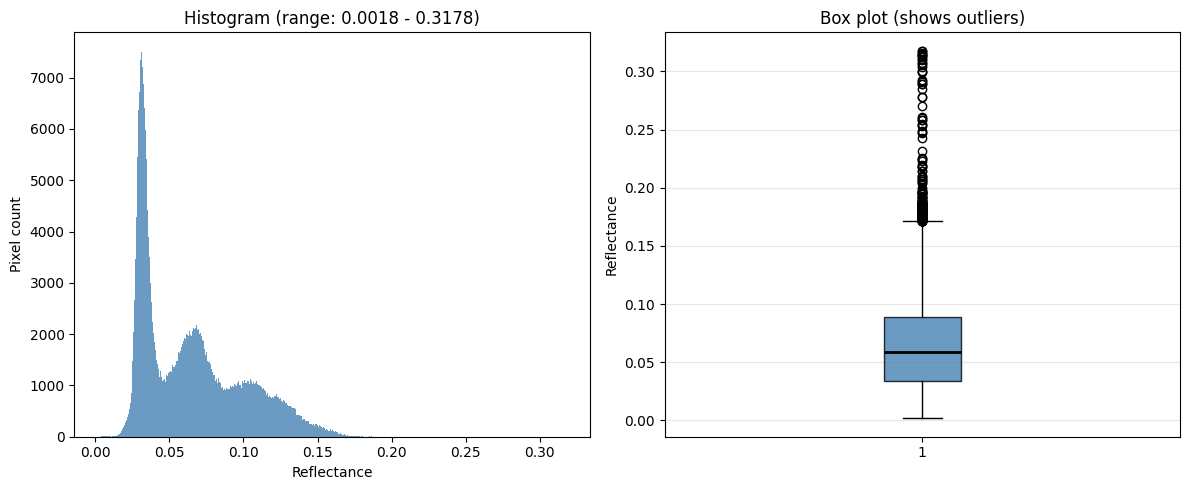

In [6]:
# Create a figure with two side-by-side plots: histogram and box plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Flatten the 2D band image into a 1D array so we can count how many pixels
# have each reflectance value (required for histogram)
flatten_image = band_image.flatten()

# each bar shows how many pixels fall within that interval
ax1.hist(flatten_image, bins=500, color='steelblue', alpha=0.8)

ax1.set_xlabel('Reflectance')
ax1.set_ylabel('Pixel count')
ax1.set_title(f'Histogram (range: {flatten_image.min():.4f} - {flatten_image.max():.4f})')

# Right: Box plot - clearly shows median, quartiles, and outliers
ax2.boxplot(flatten_image, vert=True, patch_artist=True,
            boxprops=dict(facecolor='steelblue', alpha=0.8),
            medianprops=dict(color='black', linewidth=2))
ax2.set_ylabel('Reflectance')
ax2.set_title('Box plot (shows outliers)')
ax2.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

---

### Interpreting the histogram

Interesting! The histogram reveals several important patterns, especially the distribution of values spanning roughly **0.0018 → 0.3178**. From the histogram, we can see that:

* **Most pixels are concentrated in a relatively small range** (the tall cluster on the left and the main body of the distribution).

* The distribution is **not uniform**; it is **multi-modal** (it has several bumps/peaks).
  This confirms that the image likely contains **multiple land-cover types** with different reflectance characteristics.

* There is a **long right tail** extending toward higher reflectance values.
  These pixels are relatively rare, but they push the maximum value upward.

While the histogram gives us a strong sense of the overall distribution, the box plot confirms the outlier behavior: the **upper whisker** reaches into the brighter part of the scene, and the many points above it are **outliers**. These outliers extend up toward the maximum (~0.32), meaning there are **some very bright pixels** compared to the rest of the image.

```{note}
In remote sensing, bright outliers are often caused by **clouds/snow**, **specular highlights (sun glint)**, **very bright bare surfaces**, **saturation**, or **sensor/processing artifacts**. The exact cause depends on the sensor, band and scene.
```

### Why this matters for contrast

Now we can see why the default image looked faint, as we mentioned `imshow()` by default maps **min → black** and **max → white**. So, in our case the **maximum** is pulled upward by a small number of very bright outliers. That forces the majority of pixels (the landscape signal) to occupy only a **small fraction of the grayscale**, making the image look flat and low-contrast.

### What we do next

Instead of using the absolute minimum and maximum, we will choose `vmin` and `vmax` from the **main bulk of the distribution**, typically using **percentiles** (e.g., the 2nd and 98th, or the 1st and 99th). This prevents rare outliers from dominating the display scaling and allows most landscape pixels to spread across the full grayscale range.

Next, we’ll compute percentiles and use them for `plt.imshow(..., vmin=..., vmax=...)`, then compare the old plot with the new one.

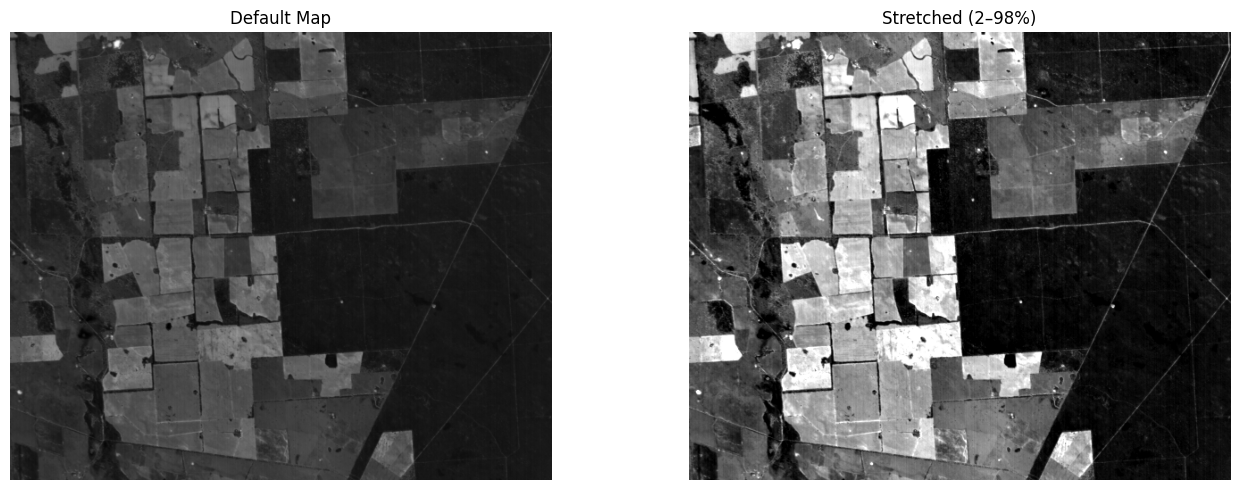

In [7]:
# Calculate percentiles
p_02, p_98 = np.percentile(band_image, (2,98))

# Plot the maps
fig, (normal_plot, stretched_plot) = plt.subplots(1, 2, figsize=(14, 5))

normal_plot.imshow(band_image, cmap='gray')
normal_plot.set_title(f"Default Map")
normal_plot.axis("off")

stretched_plot.imshow(band_image, cmap='gray', vmin=p_02, vmax=p_98)
stretched_plot.set_title(f"Stretched (2–98%)")
stretched_plot.axis("off")

fig.tight_layout()
plt.show()

Notice the difference: the 2–98% stretch dramatically improves contrast. Field boundaries, texture, and subtle land-cover transitions that were hidden or difficult to see in the default view become clearly visible.

### Beyond contrast: using `vmin`/`vmax` to *explore* the data

So far, we used `vmin` and `vmax` to improve the **visual contrast** of the image. But this same technique is useful for something even more powerful: **data exploration**.

By deliberately choosing a narrow value range (a “window”), we can make the map behave like a **highlight tool**:

* Pixels **inside** the chosen range become visible and detailed.
* Pixels **outside** the range get clipped to black or white and become less informative.
* This helps us isolate and inspect specific reflectance ranges that may correspond to different surface types.

In other words, this isn’t only about “making the image prettier”, it’s a way to **connect the histogram to the geography**.

#### Why this works especially well here (multi-modal histogram)

Our histogram is **multi-modal**, meaning it has several peaks. In remote sensing, this often happens because the scene contains **multiple land-cover types**, each with its own typical reflectance range (for example: water, vegetation, bare soil, built-up areas, clouds, etc.).

Each “bump” in the histogram is often a mixture of one or more surface classes. By selecting a small window around a peak—and plotting the map using that same window, we can start answering questions like:

* *Where are the pixels that belong to this peak located?*
* *What land features do they represent?*
* *Does this peak correspond to fields, roads, water, or something else?*

#### Let’s explore the strongest peak

Looking at the histogram, the tallest spike contains a huge number of pixels. That makes it a perfect starting point: it likely represents the **dominant surface type** in the scene.

In this next step, we’ll “zoom in” on that peak by choosing a tight `vmin`/`vmax` window (like `0.019 → 0.040`) and then plotting:

1. The **spatial map** using that window
2. The **histogram** showing exactly which part of the distribution we are viewing

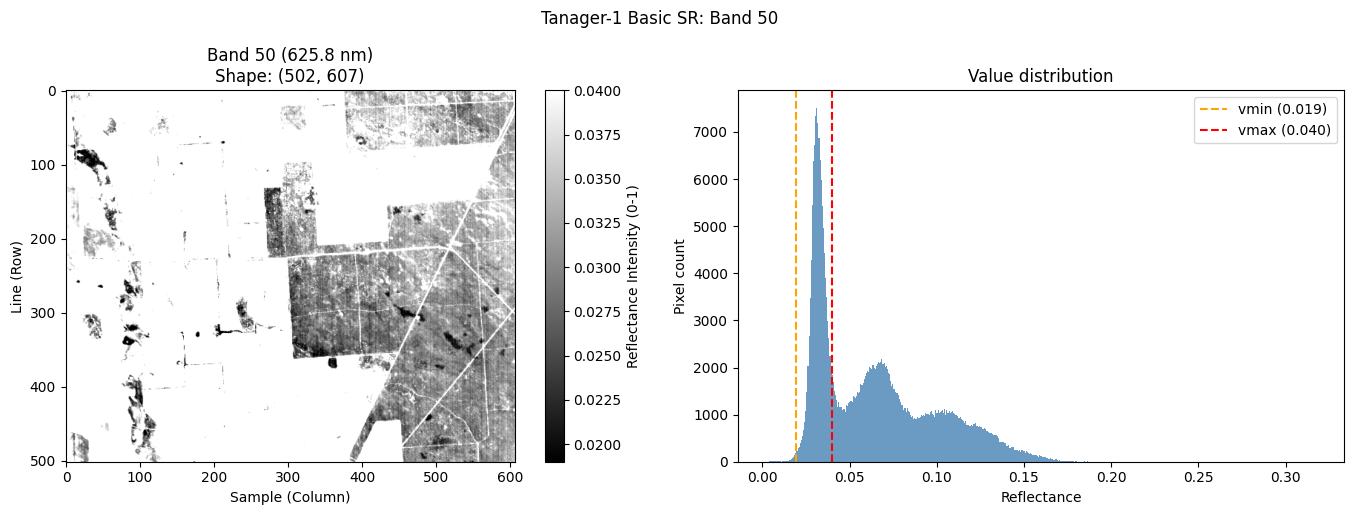

In [8]:
# Set a vmin/vmax value based on the portion of the histogram we want to focus on.
vmin = 0.019
vmax = 0.04

# Plot: Map + Value Distribution (histogram)
# The histogram shows what values we're plotting—helps verify data range, spot outliers, and interpret the map.
fig, (ax_map, ax_hist) = plt.subplots(1, 2, figsize=(14, 5))

# Left: The map
im = ax_map.imshow(band_image, cmap='gray', vmin=vmin, vmax=vmax)
plt.colorbar(im, ax=ax_map, label='Reflectance Intensity (0-1)')
ax_map.set_title(f"Band 50 ({band_wavelength:.1f} nm)\nShape: {band_image.shape}")
ax_map.set_xlabel("Sample (Column)")
ax_map.set_ylabel("Line (Row)")

# Right: Distribution of pixel values
ax_hist.hist(band_image.flatten(), bins=500, color='steelblue', alpha=0.8)
ax_hist.axvline(vmin, color='orange', linestyle='--', label=f'vmin ({vmin:.3f})')
ax_hist.axvline(vmax, color='red', linestyle='--', label=f'vmax ({vmax:.3f})')
ax_hist.set_xlabel('Reflectance')
ax_hist.set_ylabel('Pixel count')
ax_hist.set_title('Value distribution')
ax_hist.legend()

plt.suptitle('Tanager-1 Basic SR: Band 50', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

Can you see what happened? By focusing on this narrow reflectance window, we’ve revealed **fine spatial detail** that was previously buried in very dark gray tones. Features that looked nearly uniform in the default view now separate into distinct textures and boundaries. That’s the real power of histogram-guided visualization: it helps you **connect value ranges to real land patterns**.

#### I encourage you to experiment:

* Move the window to the **next bump** in the histogram
* Try a window over the **right tail** (brighter surfaces)
* Try a window over the **dark tail** (very low-reflectance features)

Each time you shift the window, ask yourself: *Which parts of the scene become clearer now—and what might they represent?* This is how you translate histogram peaks into **meaningful land features**.

---

## 🧰 Starting Your Toolkit

You just used two pieces of code that you will reach for in **every** remaining lesson:

1. **`print_structure`** — audit any Tanager-1 HDF5 file's hierarchy and attributes.
2. **The loading recipe** — open the file, point at a dataset, read its values, and read its attributes (here, the `wavelengths`).

This is the course's **build-your-own-toolkit** assignment. Instead of re-typing these every time, you will **package them into reusable functions** kept in a single **Toolkit** cell that grows lesson by lesson, by the end of the course it is your own hyperspectral analysis library.

Below is the **skeleton** of your first two tools: `print_structure` and a general loader, `load_hdf5`. The signatures and docstrings are given, **your job is to fill in the bodies** using the code you wrote above. Notice the loader is written to **generalize** that recipe: rather than hard-coding the `surface_reflectance` cube and the single `wavelengths` attribute, it loads **any dataset** at `data_path` and hands back its data plus **all** of its properties (attributes) as a dict, so the very same function will later load masks, geometry layers, and Ortho cubes without a rewrite. An optional `band=` argument lets it lazily read a single 2-D band straight from disk when you don't need the whole cube.

Your Toolkit also starts with one function **we wrote for you**: `download_tanager_data`, the packaged version of the download cell you ran above. You don't implement this one, just call it at the top of every lesson that needs data. It travels with your Toolkit from the next lesson on.

```{tip}
Try to implement both `print_structure` and `load_hdf5` yourself before moving on. You'll find the **reference solution** at the top of the next coding lesson, **Module 2 · Lesson 3: Basic vs Ortho**, where you'll put the loader straight to work on both Basic and Ortho files. The loader keeps growing later, quality-cleaning joins it in **Module 3 · Lesson 1**.
```

### Provided for you: `download_tanager_data`

You don't implement this one, it's the packaged version of the download cell you ran at the top of this lesson. It fetches a scene's `.h5` file (and skips the download when the file is already on disk). Keep it at the top of your Toolkit and call it whenever a lesson needs data.

In [9]:
def download_tanager_data(url, file_path):
    """Download a Tanager-1 data file to disk if it isn't already there.

    Provided for you — you don't need to implement this one. It streams the file
    from ``url`` to ``file_path`` with a simple MB progress readout and skips the
    download when the file already exists, so re-running a lesson stays cheap.
    Returns ``file_path`` so you can hand it straight to ``load_tanager_hdf5``.

    Parameters
    ----------
    url : str
        Public URL of the ``.h5`` file.
    file_path : str
        Local filename to save to (also checked before downloading).

    Returns
    -------
    str
        The local ``file_path``, ready to load.
    """
    import os
    import urllib.request

    def _progress(count, block_size, total_size):
        mb_done = count * block_size / 1_000_000
        mb_total = total_size / 1_000_000
        print(f"\rDownloading... {mb_done:.1f} / {mb_total:.1f} MB", end="", flush=True)

    if not os.path.exists(file_path):
        urllib.request.urlretrieve(url, file_path, reporthook=_progress)
        print(f"\nDownload complete: {file_path}")
    else:
        print(f"File already exists, skipping download: {file_path}")
    return file_path

In [10]:
# =====================================================================
# 🧰 TOOLKIT — YOUR TURN  (implement before the next lesson)
# Fill in the bodies below; the reference solution appears at the top
# of the next coding lesson (Module 2 · Lesson 3: Basic vs Ortho).
# =====================================================================

# Import necessary libraries

import h5py
import numpy as np

# ---- io ----------------------------------------------------------------

def print_structure(name, obj):
    """
    Print one HDF5 object (group or dataset) plus its attributes.

    Designed as a callback for ``h5py.File.visititems`` to render the full
    hierarchy of a Tanager-1 file as an indented tree.

    Parameters
    ----------
    name : str
        Full HDF5 path of the object (provided by ``visititems``).
    obj : h5py.Group or h5py.Dataset
        The object itself (provided by ``visititems``).
    """
    # TODO: indent by depth (count '/'); print groups as "📂 name/" and
    #       datasets as "📄 name | shape | dtype"; then dump each object's
    #       attributes on indented "↳ 🏷️ key: value" lines.
    pass

def load_hdf5(
    file_path,
    data_path='HDFEOS/SWATHS/HYP/Data Fields/surface_reflectance',
    band=None):
    """Load a dataset (or one band) from a Tanager-1 HDF5 file, with its properties.

    Works for ANY dataset in the file — reflectance cubes, masks, geometry layers —
    because it never assumes what the values mean. Pass ``band`` to lazily read a
    single 2-D band straight from disk (cheap on RAM); leave it ``None`` for the
    full array.

    Parameters
    ----------
    file_path : str
        Path to the Tanager-1 ``.h5`` file.
    data_path : str, optional
        Internal HDF5 path to the dataset (Basic ``…/SWATHS/…`` by default; switch
        to ``…/GRIDS/…`` for Ortho, or to any mask / geometry layer).
    band : int, optional
        If given, read only that band index (lazy slice); if ``None``, read all.

    Returns
    -------
    data : ndarray
        The full array, or a single 2-D band if ``band`` is given.
    attrs : dict
        All attributes (properties) of the dataset — e.g. ``'wavelengths'``,
        ``'units'``, ``'good_wavelengths'``.
    """
    # TODO: open file_path with h5py; select the dataset at data_path; read the whole
    #       array, or just dset[band] when band is not None, into `data`; copy the
    #       dataset's attributes into a dict `attrs`; return (data, attrs).
    pass

---

## Summary & Next Steps

Congratulations. You have successfully navigated the transition from synthetic training data to **Operational Satellite Imagery**.

In this lesson, you achieved four critical milestones:

1. Acquisition: You retrieved a massive Tanager-1 dataset from Planet's Open STAC catalog.

2. Audit: You used recursive mapping to penetrate the complex HDF-EOS hierarchy.

3. Extraction: You identified the key dataset in the file—the Reflectance Cube and its spectral wavelengths.

4. Visualization: You converted raw 3D arrays into a visible map of the Earth's surface.

…and you **started your Toolkit** with `print_structure` and `load_tanager_hdf5`.

**But we ignored something important.**

When you looked at the STAC Catalog, you saw a confusing list of other files: ortho_reflectance, basic_radiance, geolocation_array.

- Should you use Basic or Ortho?

- Do you need Radiance or Reflectance?

**Next Up:** In the next lesson, we will decode the Tanager-1 asset ecosystem. We will learn exactly which file to pick for your specific science goal and how to use the Visual and UDM assets to quality-check your data before you process it.

See you in **Lesson 2 of Module 2: The Tanager-1 Asset Ecosystem**!